In [10]:
#1️⃣ Imports + Config
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import cv2
from sklearn.metrics import confusion_matrix
import seaborn as sns
import pandas as pd

DATASET_PATH = "/kaggle/input/datasets/paultimothymooney/breast-histopathology-images"

IMG_SIZE = 50
BATCH_SIZE = 32
SEED = 42

2026-03-06 14:40:41.655565: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772808041.897454      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772808041.967084      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772808042.519290      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772808042.519342      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772808042.519345      55 computation_placer.cc:177] computation placer alr

In [11]:
# 2️⃣ Load Dataset
def load_all_paths():
    image_paths = []
    labels = []
    patient_ids = []

    for patient in os.listdir(DATASET_PATH):
        patient_path = os.path.join(DATASET_PATH, patient)

        if not os.path.isdir(patient_path):
            continue

        for label in ["0","1"]:
            label_path = os.path.join(patient_path,label)

            if not os.path.exists(label_path):
                continue

            for file in os.listdir(label_path):
                image_paths.append(os.path.join(label_path,file))
                labels.append(int(label))
                patient_ids.append(patient)

    return np.array(image_paths), np.array(labels), np.array(patient_ids)

paths, labels, patient_ids = load_all_paths()

print("Total images:", len(paths))
print("Benign:", np.sum(labels==0))
print("Malignant:", np.sum(labels==1))


Total images: 277524
Benign: 198738
Malignant: 78786


In [12]:
# 3️⃣ Patient-Level Split
# label لكل patient
patient_labels = {}

for p,l in zip(patient_ids, labels):

    if p not in patient_labels:
        patient_labels[p] = l
    else:
        patient_labels[p] = max(patient_labels[p], l)

patients = np.array(list(patient_labels.keys()))
labels_per_patient = np.array(list(patient_labels.values()))

# Stratified split
train_patients, test_patients = train_test_split(
    patients,
    test_size=0.2,
    random_state=SEED,
    stratify=labels_per_patient
)

train_mask = np.isin(patient_ids, train_patients)
test_mask = np.isin(patient_ids, test_patients)

train_paths = paths[train_mask]
y_train = labels[train_mask]

test_paths = paths[test_mask]
y_test = labels[test_mask]

test_patient_ids = patient_ids[test_mask]

print("Train samples:", len(train_paths))
print("Test samples:", len(test_paths))


Train samples: 225545
Test samples: 51979


In [13]:
print(len(np.unique(train_patients)))
print(len(np.unique(test_patients)))

223
56


In [14]:
# 4️⃣ Preprocessing
def preprocess(path,label):

    img = tf.io.read_file(path)
    img = tf.image.decode_png(img,channels=3)

    img = tf.image.resize(img,[IMG_SIZE,IMG_SIZE])
    img = img / 255.0

    return img,label

In [15]:
# 5️⃣ Data Augmentation

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])


2026-03-06 14:41:33.824519: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [16]:
# 6️⃣ tf.data Pipeline


train_ds = tf.data.Dataset.from_tensor_slices((train_paths,y_train))
train_ds = train_ds.map(preprocess)

train_ds = train_ds.map(
    lambda x,y:(data_augmentation(x,training=True),y)
)

train_ds = train_ds.shuffle(10000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


test_ds = tf.data.Dataset.from_tensor_slices((test_paths,y_test))
test_ds = test_ds.map(preprocess)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [17]:
# 7️⃣ Class Weights
class_weights = class_weight.compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(enumerate(class_weights))

print(class_weights)

{0: np.float64(0.6999069045771916), 1: np.float64(1.7505821173548588)}


In [18]:
# 8️⃣ CNN Model
model = models.Sequential([

    layers.Input(shape=(50,50,3)),

    layers.Conv2D(32,(3,3),padding='same',
                  activation='relu',
                  kernel_regularizer=regularizers.l2(1e-4)),

    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.2),

    layers.Conv2D(64,(3,3),padding='same',
                  activation='relu',
                  kernel_regularizer=regularizers.l2(1e-4)),

    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.3),

    layers.Conv2D(128,(3,3),padding='same',
                  activation='relu',
                  kernel_regularizer=regularizers.l2(1e-4)),

    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64,activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1,activation='sigmoid')
])

In [19]:
# 9️⃣ Compile (Lower LR)
model.compile(

    optimizer=tf.keras.optimizers.Adam(3e-5),

    loss='binary_crossentropy',

    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [20]:
# 🔟 Callbacks
early_stop = EarlyStopping(

    monitor="val_auc",
    patience=3,
    mode="max",
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-6
)

checkpoint = ModelCheckpoint(

    "best_model.keras",
    monitor="val_auc",
    save_best_only=True,
    mode="max",
    verbose=1
)

In [21]:
# 1️⃣1️⃣ Train
history = model.fit(

    train_ds,

    epochs=15,

    validation_data=test_ds,

    class_weight=class_weights,

    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ]
)

Epoch 1/15
7048/7049 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.8200 - auc: 0.8851 - loss: 0.4371
Epoch 1: val_auc improved from -inf to 0.88277, saving model to best_model.keras
7049/7049 ━━━━━━━━━━━━━━━━━━━━ 1042s 144ms/step - accuracy: 0.8200 - auc: 0.8851 - loss: 0.4371 - val_accuracy: 0.7989 - val_auc: 0.8828 - val_loss: 0.4730 - learning_rate: 3.0000e-05
Epoch 2/15
7048/7049 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.8461 - auc: 0.9156 - loss: 0.3793
Epoch 2: val_auc improved from 0.88277 to 0.89315, saving model to best_model.keras
7049/7049 ━━━━━━━━━━━━━━━━━━━━ 994s 139ms/step - accuracy: 0.8461 - auc: 0.9156 - loss: 0.3793 - val_accuracy: 0.7742 - val_auc: 0.8932 - val_loss: 0.5232 - learning_rate: 3.0000e-05
Epoch 3/15
7048/7049 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.8496 - auc: 0.9214 - loss: 0.3669
Epoch 3: val_auc improved from 0.89315 to 0.90323, saving model to best_model.keras
7049/7049 ━━━━━━━━━━━━━━━━━━━━ 917s 128ms/step - accuracy: 0.8496 - auc:

In [22]:
best_threshold = 0.5
preds = model.predict(test_ds).ravel()

from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report

# AUC
auc = roc_auc_score(y_test, preds)
print("Test ROC-AUC:", auc)

# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, preds)

best_idx = np.argmax(tpr - fpr)
best_threshold = thresholds[best_idx]

print("Best Threshold:", best_threshold)

# Predictions
y_pred = (preds >= best_threshold).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

1625/1625 ━━━━━━━━━━━━━━━━━━━━ 49s 30ms/step
Test ROC-AUC: 0.9064753075459517
Best Threshold: 0.57680005
Confusion Matrix:
[[31120  6493]
 [ 2156 12210]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.83      0.88     37613
           1       0.65      0.85      0.74     14366

    accuracy                           0.83     51979
   macro avg       0.79      0.84      0.81     51979
weighted avg       0.86      0.83      0.84     51979



In [73]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name):

    last_conv_layer = model.get_layer(last_conv_layer_name)

    grad_model = tf.keras.models.Model(
        inputs=model.layers[0].input,
        outputs=[last_conv_layer.output, model.layers[-1].output],
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)

    return heatmap.numpy()

In [75]:
import random
img_path = random.choice(test_paths)

img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE)) / 255.0
img_array = np.expand_dims(img_resized, axis=0)

In [76]:
pred = model.predict(img_array)[0][0]

print("Prediction probability:", pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Prediction probability: 0.9097259


In [77]:
for layer in model.layers:
    print(layer.name)

conv2d
batch_normalization
max_pooling2d
dropout
conv2d_1
batch_normalization_1
max_pooling2d_1
dropout_1
conv2d_2
batch_normalization_2
max_pooling2d_2
global_average_pooling2d
dense
dropout_2
dense_1


In [78]:
# ابني نسخة Functional من الموديل
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = inputs
for layer in model.layers:
    x = layer(x)

functional_model = tf.keras.Model(inputs, x)

# اعمل forward pass عشان يتبني graph
_ = functional_model(img_array)

In [80]:
# شغل الموديل مرة عشان يبني graph
_ = model(img_array)

# GradCAM
heatmap = make_gradcam_heatmap(img_array, model, "conv2d_2")

heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.13333333333333333..1.2133149974486406].


(np.float64(-0.5), np.float64(49.5), np.float64(49.5), np.float64(-0.5))

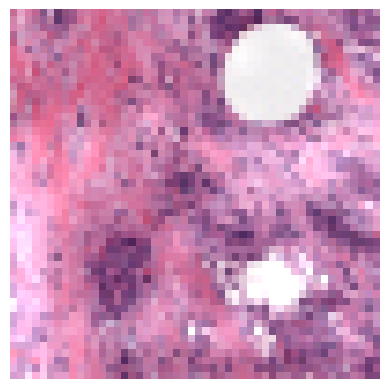

In [81]:
plt.imshow(heatmap, cmap="jet")
plt.axis("off")
overlay = img/255 + heatmap[..., np.newaxis]*0.5

plt.imshow(overlay)
plt.axis("off")

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.13333333333333333..1.2133149974486406].


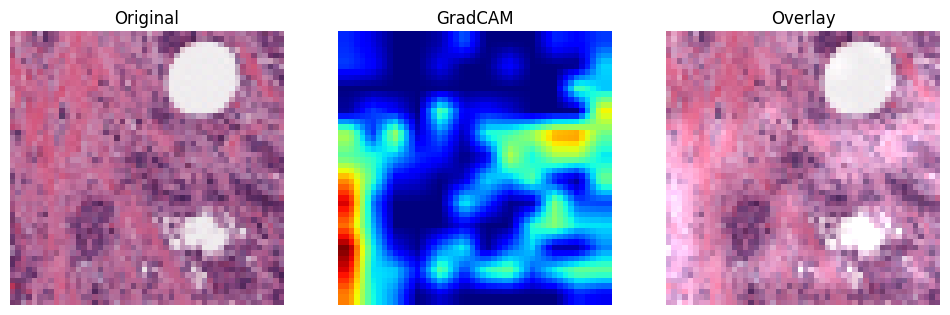

In [82]:
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.title("Original")
plt.imshow(img)
plt.axis("off")

plt.subplot(1,3,2)
plt.title("GradCAM")
plt.imshow(heatmap, cmap="jet")
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Overlay")

overlay = img/255 + heatmap[..., np.newaxis]*0.5
plt.imshow(overlay)
plt.axis("off")

plt.show()

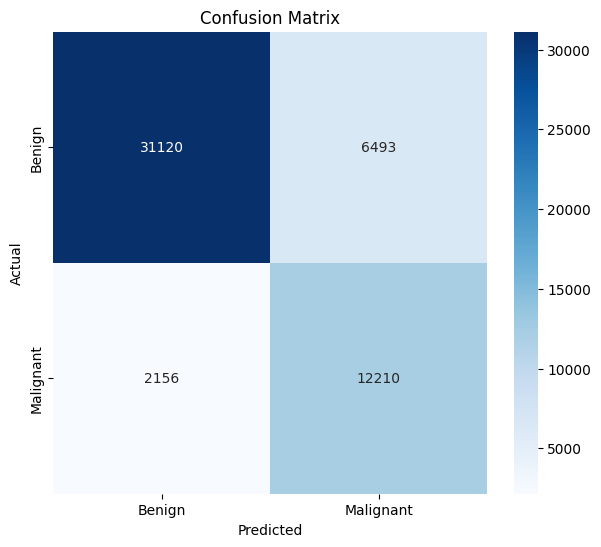

In [83]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign","Malignant"],
    yticklabels=["Benign","Malignant"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

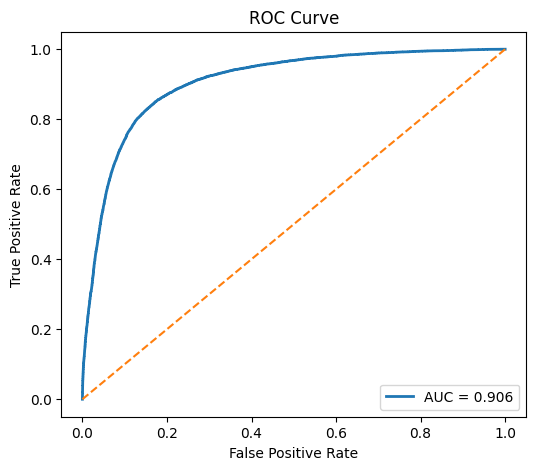

In [84]:
plt.figure(figsize=(6,5))

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}", linewidth=2)
plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend(loc="lower right")
plt.show()

In [86]:
model.save("breast_cancer_model.keras")